In [17]:
import json
import sys
from collections import Counter

import matplotlib.pyplot as plt

with open("species_description.json", encoding="utf-8") as f:
    data = json.load(f)

In [ ]:

# 1. How many species
print("Total species:", len(data))

# 2. First few names
print("First 5:", list(data)[:5])

# 3. Accepted vs not
print("is accepted:", Counter(r.get("is accepted", "") for r in data.values()))

# 4. Species per genus (top 10)
print("Per genus:", Counter(r.get("genus", "") for r in data.values()).most_common(10))

# 5. Which fields exist, and how many species have a NON-EMPTY value
field_filled = Counter()
field_present = Counter()
for r in data.values():
    for k, v in r.items():
        field_present[k] += 1
        if str(v).strip():
            field_filled[k] += 1

print(f"\n{'field':35} present  filled")
for k, n in field_present.most_common():
    print(f"{k:35} {n:7}  {field_filled[k]:6}")


# 6. Missing barcodes / genomes
print("\nNo ITS:", sum(1 for r in data.values() if not r.get("ITS GenBank ID")))
print("Has genome (WGS_type):", sum(1 for r in data.values() if r.get("WGS_type")))

Total species: 1609
First 5: ['Acidotalaromyces lignorum', 'Ascospirella lutea', 'Aspergillago clavatoflava', 'Aspergillus acanthosporus', 'Aspergillus acidohumus']
is accepted: Counter({'Yes': 1486, 'No': 123})
Per genus: [('Penicillium', 664), ('Aspergillus', 478), ('Talaromyces', 247), ('', 125), ('Paecilomyces', 17), ('Rasamsonia', 16), ('Hamigera', 9), ('Monascus', 9), ('Thermoascus', 7), ('Sagenomella', 6)]

field                               present  filled
is accepted                            1609    1609
Literature                             1592    1592
YEAR                                   1486    1486
MYCOBANK                               1486    1486
TYPUS                                  1486    1486
EX_TYPUS                               1485    1485
kingdom                                1485    1485
phylum                                 1485    1485
class                                  1485    1484
order                                  1485    1484
family    

In [15]:
# %pip install matplotlib

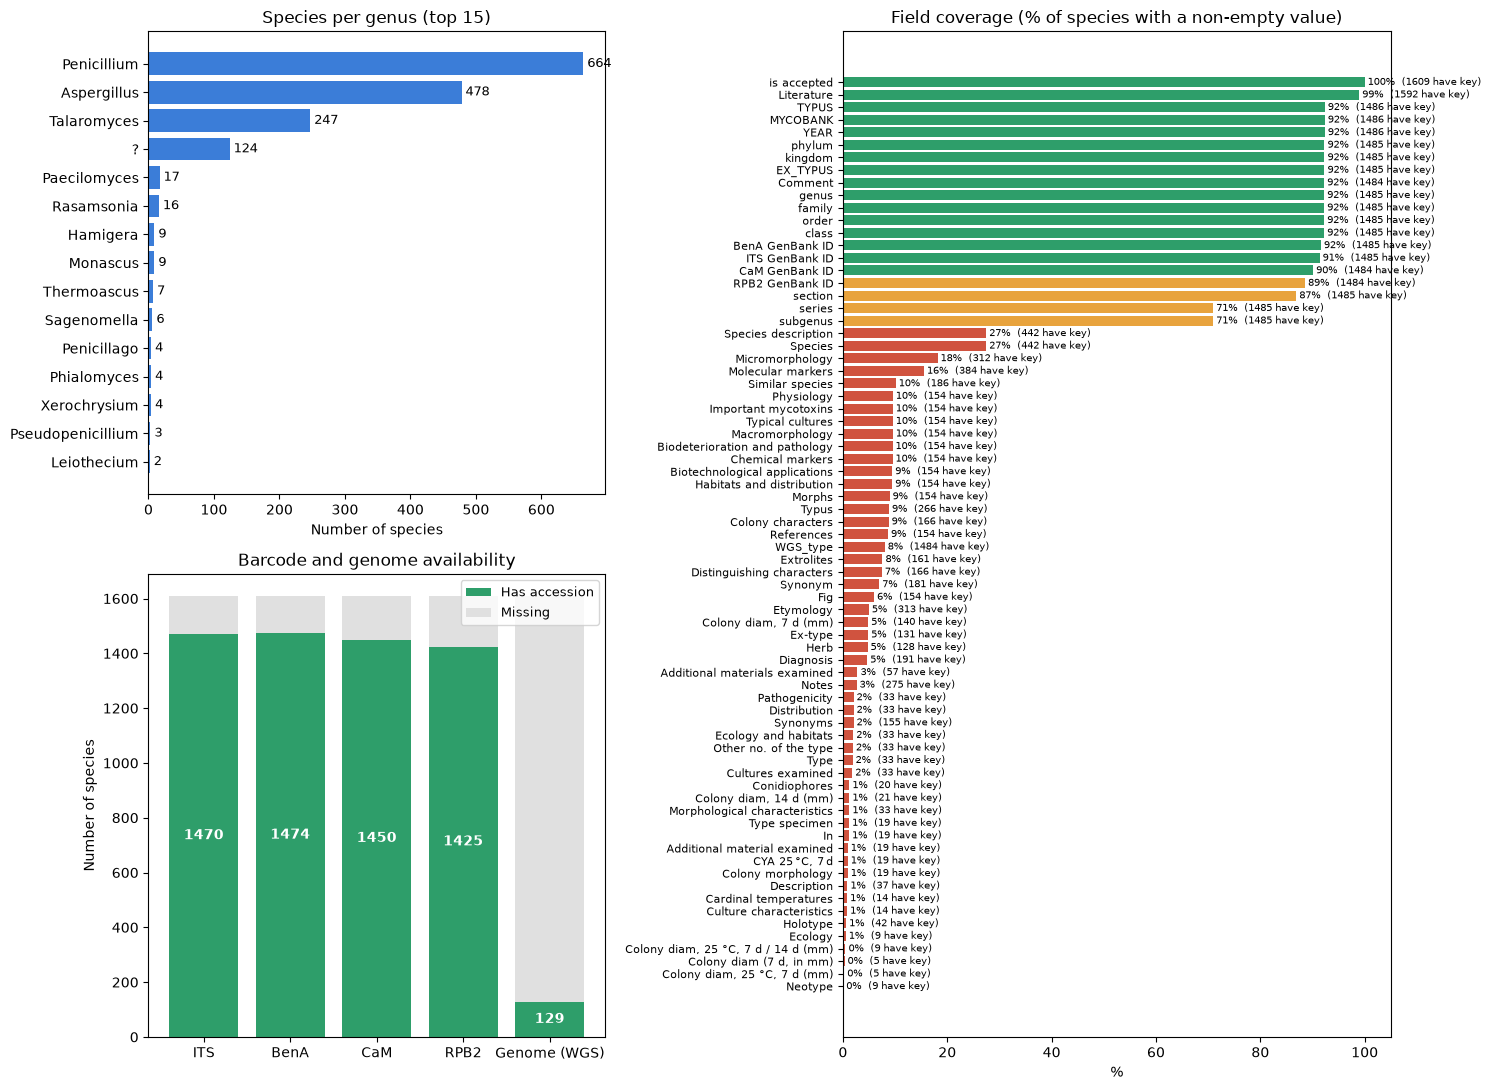

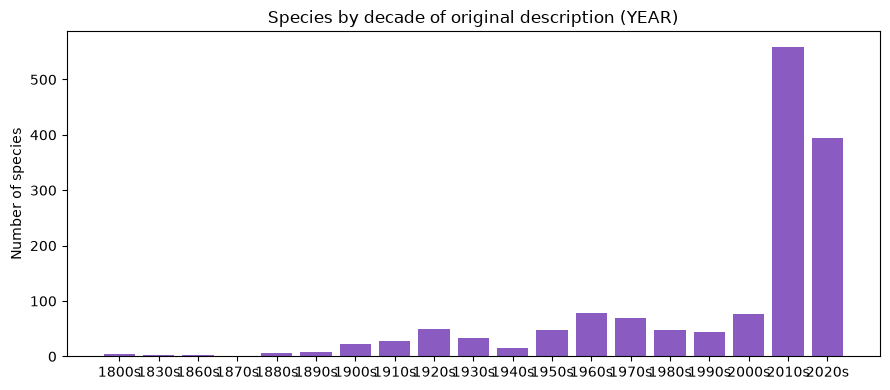

In [18]:
"""
Overview charts (dict keyed by species name).
"""

path = sys.argv[1] if len(sys.argv) > 1 else "data.json"
out = sys.argv[2] if len(sys.argv) > 2 else None

records = list(data.values())
n = len(records)

def filled(r, key):
    return bool(str(r.get(key, "")).strip())

# ---- 1. Species per genus (top 15) -------------------------------------
genus_counts = Counter(r.get("genus", "?") for r in records).most_common(15)

# ---- 2. Barcode / genome availability ----------------------------------
markers = ["ITS GenBank ID", "BenA GenBank ID", "CaM GenBank ID",
           "RPB2 GenBank ID", "WGS_type"]
marker_labels = ["ITS", "BenA", "CaM", "RPB2", "Genome (WGS)"]
have = [sum(filled(r, m) for r in records) for m in markers]
missing = [n - h for h in have]

# ---- 3. Field coverage: % of species with a non-empty value ------------
present = Counter(k for r in records for k in r)
fill = {k: 100 * sum(filled(r, k) for r in records) / n for k in present}
fields = sorted(fill, key=fill.get)          # emptiest at the bottom

# ---- 4. Species described per decade -----------------------------------
decades = Counter()
for r in records:
    y = str(r.get("YEAR", "")).strip()
    if y.isdigit():
        decades[int(y) // 10 * 10] += 1
dec_sorted = sorted(decades)

# ---- Plot --------------------------------------------------------------
fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.2])

ax1 = fig.add_subplot(gs[0, 0])
names, counts = zip(*genus_counts) if genus_counts else ([], [])
ax1.barh(names[::-1], counts[::-1], color="#3b7dd8")
ax1.set_title("Species per genus (top 15)")
ax1.set_xlabel("Number of species")
for i, c in enumerate(counts[::-1]):
    ax1.text(c, i, f" {c}", va="center", fontsize=9)

ax2 = fig.add_subplot(gs[1, 0])
ax2.bar(marker_labels, have, color="#2e9e6a", label="Has accession")
ax2.bar(marker_labels, missing, bottom=have, color="#e0e0e0", label="Missing")
ax2.set_title("Barcode and genome availability")
ax2.set_ylabel("Number of species")
ax2.legend(loc="upper right", fontsize=9)
for i, h in enumerate(have):
    ax2.text(i, h / 2, f"{h}", ha="center", va="center", color="white",
             fontweight="bold")

ax3 = fig.add_subplot(gs[:, 1])
colors = ["#2e9e6a" if fill[k] >= 90 else "#e8a33d" if fill[k] >= 30
          else "#d0533f" for k in fields]
ax3.barh(fields, [fill[k] for k in fields], color=colors)
ax3.set_xlim(0, 105)
ax3.set_title("Field coverage (% of species with a non-empty value)")
ax3.set_xlabel("%")
ax3.tick_params(axis="y", labelsize=8)
for i, k in enumerate(fields):
    ax3.text(fill[k], i, f" {fill[k]:.0f}%  ({present[k]} have key)",
             va="center", fontsize=7)

fig.tight_layout()

# Decade chart as a separate figure (it is a different question)
fig2, ax4 = plt.subplots(figsize=(9, 4))
ax4.bar([f"{d}s" for d in dec_sorted], [decades[d] for d in dec_sorted],
        color="#8a5cc2")
ax4.set_title("Species by decade of original description (YEAR)")
ax4.set_ylabel("Number of species")
fig2.tight_layout()

if out:
    fig.savefig(out, dpi=130)
    fig2.savefig(out.replace(".png", "_decades.png"), dpi=130)
    print("Saved", out, "and", out.replace(".png", "_decades.png"))
else:
    plt.show()

In [20]:
cols = Counter(k for r in data.values() for k in r)

print("Distinct columns:", len(cols))
print("Columns per species:", Counter(len(r) for r in data.values()))
for k, n in cols.most_common():
    print(f"{n:5}  {k}")

Distinct columns: 73
Columns per species: Counter({21: 1165, 33: 86, 19: 72, 30: 56, 38: 56, 36: 35, 32: 27, 34: 24, 17: 24, 10: 17, 46: 9, 44: 8, 49: 6, 14: 6, 37: 4, 42: 2, 35: 2, 27: 2, 18: 2, 47: 1, 50: 1, 41: 1, 5: 1, 25: 1, 15: 1})
 1609  is accepted
 1592  Literature
 1486  YEAR
 1486  MYCOBANK
 1486  TYPUS
 1485  EX_TYPUS
 1485  kingdom
 1485  phylum
 1485  class
 1485  order
 1485  family
 1485  genus
 1485  subgenus
 1485  section
 1485  series
 1485  ITS GenBank ID
 1485  BenA GenBank ID
 1484  CaM GenBank ID
 1484  RPB2 GenBank ID
 1484  WGS_type
 1484  Comment
  442  Species
  442  Species description
  384  Molecular markers
  313  Etymology
  312  Micromorphology
  275  Notes
  266  Typus
  191  Diagnosis
  186  Similar species
  181  Synonym
  166  Colony characters
  166  Distinguishing characters
  161  Extrolites
  155  Synonyms
  154  Macromorphology
  154  Morphs
  154  Chemical markers
  154  Typical cultures
  154  Important mycotoxins
  154  Habitats and distrib